# Lab 9 — Computing, Serialization, Autograd & Memory
**ARTI 303 — Programming for AI**

**Name:** _[Reena Aloraini]_  **Student ID:** _[2220002781]_  **Section:** _[FG1]_

---

### What this lab is really about


1. **Where does computation happen?**
2. **How is a tensor saved?**
3. **What does `requires_grad=True` enable?**
4. **Why can large workloads run out of memory?**

By the end of this lab you can answer all four **with code you ran**.


| Part | topic | You will be able to |
|---|---|---|
| 1 | CPU vs. GPU | measure when a GPU helps, and when it doesn't |
| 2 | Tensor serialization | save and restore tensors with `torch.save` and `torch.load` |
| 3 | Autograd | calculate gradients automatically and read the result |
| 4 | Memory | estimate how much memory a tensor or a batch needs |

After Part 4 there is a short AI checkpoint and a list of resources.

---

## Where to run this lab

Part 1 is far more interesting with a **GPU**. You don't need to own one.
Pick **one** of these:

| Option | GPU? | How |
|---|---|---|
| **A. Google Colab** (in the browser) | yes, free | Open [colab.research.google.com](https://colab.research.google.com), then **File → Upload notebook** and choose this file. Then **Runtime → Change runtime type** and pick a **GPU**. |
| **B. Colab inside VS Code** | yes, free | Install the **Colab** extension by Google (it needs the Jupyter extension too). Open this notebook, click **Select Kernel → Colab**, sign in with Google, and choose a runtime. You keep your VS Code and your Git workflow. |
| **C. Kaggle Notebooks** | yes, free | On [kaggle.com](https://www.kaggle.com) choose **Create → New Notebook**, then **File → Import Notebook**. In **Settings**, set the **Accelerator** to a GPU. Kaggle may ask you to verify your phone number. |
| **D. Your own computer** | only if it has one | Everything works on a CPU. A Mac with Apple silicon has a GPU PyTorch can use (called **MPS**). |

A few things to know:

- Free GPUs are **shared**, so one may not always be available. If you
  don't get one, carry on with the CPU: every exercise still passes.
- In Colab and Kaggle your files **disappear when the session ends**.
  Before you close it, download your finished notebook
  (**File → Download → `.ipynb`**) and put it in your course folder.
- With option B the code runs on **Colab's computer**, so files the
  notebook creates appear there, not in your own folder.

**Running on your own computer?** It's the same course folder and
environment as Lab 8: open `arti303_lab` in VS Code and activate `.venv`
(your prompt must show `(.venv)`). PyTorch is already installed.

### Check where you are

In [ ]:
%pip install torch

In [5]:
import os
import sys
import time
import math

import torch


def where_am_i():
    if "google.colab" in sys.modules:
        return "Google Colab"
    if os.path.exists("/kaggle"):
        return "Kaggle"
    return "your own computer"


place = where_am_i()
print("running on: ", place)
print("python:     ", sys.version.split()[0])
print("torch:      ", torch.__version__)

if torch.cuda.is_available():
    device = "cuda"
    print("accelerator: NVIDIA GPU -", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    device = "mps"
    print("accelerator: Apple GPU (MPS)")
else:
    device = "cpu"
    print("accelerator: none (CPU only)")

print()
if place == "your own computer" and sys.prefix == sys.base_prefix:
    print("[!] You are not inside a virtual environment: select the .venv interpreter, then restart the kernel.")
elif device == "cpu" and place in ("Google Colab", "Kaggle"):
    print("[i] No GPU yet. Colab: Runtime -> Change runtime type -> pick a GPU. Kaggle: Settings -> Accelerator.")
elif device == "cpu":
    print("[i] CPU only. That's fine: every exercise works. Try Colab if you want to see a GPU in action.")
else:
    print("[ok] A GPU is available. This lab will use:", device)

os.makedirs("data", exist_ok=True)

running on:  Google Colab
python:      3.13.16
torch:       2.11.0+cu130
accelerator: NVIDIA GPU - Tesla T4

[ok] A GPU is available. This lab will use: cuda


---
# Part 1 · CPU vs. GPU

where computations happen.*

| | CPU | GPU |
|---|---|---|
| Design | a few powerful, flexible cores | thousands of simpler units working together |
| Good at | program logic, varied tasks, small calculations | the **same** operation on huge amounts of numbers |
| Typical AI use | data preparation, small computations | large matrix and tensor computations |


Every tensor has a `device`. By default it is on the CPU:

In [6]:
x = torch.tensor([1.0, 2.0, 3.0])

print("x lives on:               ", x.device)
print("CUDA (NVIDIA) available:  ", torch.cuda.is_available())
print("MPS (Apple GPU) available:", torch.backends.mps.is_available())
print("this lab will use:        ", device)

x lives on:                cpu
CUDA (NVIDIA) available:   True
MPS (Apple GPU) available: False
this lab will use:         cuda


You move a tensor with `.to(device)`. A calculation runs **where its
tensors live**, and tensors in one operation must be on the **same**
device:

In [7]:
x_on_device = x.to(device)
y = x_on_device * 2

print("x_on_device is on:", x_on_device.device)
print("y is on:          ", y.device)

if device != "cpu":
    try:
        x + x_on_device
    except RuntimeError as error:
        print()
        print("mixing devices fails:", str(error)[:110])
else:
    print()
    print("(On a GPU runtime this cell also shows the error you get when mixing devices.)")

x_on_device is on: cuda:0
y is on:           cuda:0

mixing devices fails: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu!


### Activity 1: CPU or GPU?

Think about it, then answer in code.

- **Scenario A:** calculate the sum of 10 numbers.
- **Scenario B:** multiply two very large matrices, repeatedly.

Fill in:

- `gpu_scenario`: `"A"` or `"B"`, the one more likely to benefit from a GPU
- `gpu_guaranteed`: `True` or `False`, does a GPU **guarantee** faster execution?
- `small_op_reason`: why might a CPU be better for a very small operation? Choose one:
  - `"overhead"`: GPU setup and data-transfer overhead can outweigh the benefit
  - `"cores"`: a CPU always has more cores than a GPU
  - `"memory"`: a GPU has no memory

In [8]:
gpu_scenario = "B"
gpu_guaranteed = False
small_op_reason = "overhead"


In [9]:
assert gpu_scenario is not None and gpu_guaranteed is not None and small_op_reason is not None, "fill in all three"
assert gpu_scenario == "B", "think about which task has a huge number of similar calculations to run side by side"
assert gpu_guaranteed is False, "the lecture's key message: a GPU does not guarantee faster execution"
assert small_op_reason == "overhead", "for tiny jobs, getting the data to the GPU can cost more than the calculation itself"
print("Exercise 1.1 correct.")

Exercise 1.1 correct.


### Let's measure it

**Time** a matrix multiplication
`C = A × B` on the CPU and on the GPU, for growing sizes.

Two traps make GPU timings wrong, so the helper below handles both:

1. **Warm-up.** The first call is slower (the device is getting ready), so
   run it once before timing.
2. **GPU work is asynchronous.** Python carries on *before* the GPU has
   finished. Without `synchronize()` you stop the clock too early and
   measure nothing. (It is the same kind of trap as the lazy `.collect()`
   in Assignment 1.)

In [10]:
def sync(device):
    """Wait until the device has really finished its work."""
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()


def time_it(fn, device, repeats=5):
    """Average seconds per call of fn(), measured properly."""
    fn()
    sync(device)                       # warm-up, not timed
    start = time.perf_counter()
    for _ in range(repeats):
        fn()
    sync(device)                       # wait for the device before stopping the clock
    return (time.perf_counter() - start) / repeats


def time_matmul(n, device):
    a = torch.rand(n, n, device=device)
    b = torch.rand(n, n, device=device)
    return time_it(lambda: a @ b, device)

  size   CPU (ms)  CUDA (ms)  GPU faster by
    32      0.017      0.045           0.4x
   128      0.058      0.039           1.5x
   512      2.150      0.142          15.1x
  1024     16.812      0.840          20.0x
  2048    174.956      6.045          28.9x


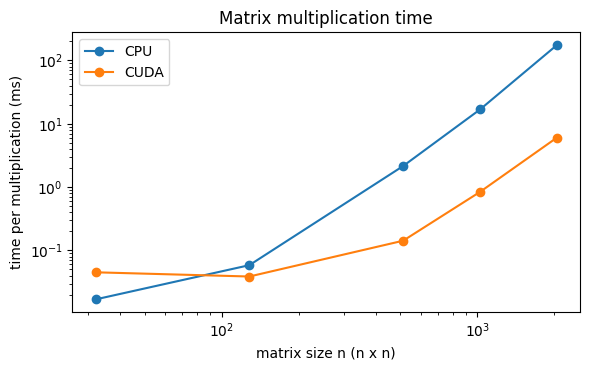

In [11]:
import matplotlib.pyplot as plt

sizes = [32, 128, 512, 1024, 2048]
cpu_times = [time_matmul(n, "cpu") for n in sizes]
accel_times = [time_matmul(n, device) for n in sizes] if device != "cpu" else None

header = f"{'size':>6} {'CPU (ms)':>10}"
if accel_times:
    header += f" {device.upper() + ' (ms)':>10} {'GPU faster by':>14}"
print(header)
for i, n in enumerate(sizes):
    row = f"{n:>6} {cpu_times[i] * 1000:>10.3f}"
    if accel_times:
        row += f" {accel_times[i] * 1000:>10.3f} {cpu_times[i] / accel_times[i]:>13.1f}x"
    print(row)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(sizes, [t * 1000 for t in cpu_times], "o-", label="CPU")
if accel_times:
    ax.plot(sizes, [t * 1000 for t in accel_times], "o-", label=device.upper())
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("matrix size n (n x n)")
ax.set_ylabel("time per multiplication (ms)")
ax.set_title("Matrix multiplication time")
ax.legend()
fig.tight_layout()

**What to look for.** On a computer with a GPU, compare the two columns:
for the smallest sizes the CPU is often as fast or faster, and for the
largest sizes the GPU should win clearly. The exact numbers depend on your hardware.

If you are running on a CPU only, just the CPU column fills in. Run this
notebook on Colab to see both side by side.

### Exercise 1.2
multiply many numbers by 2 (yᵢ = xᵢ × 2).

Write `time_scale(n, device)`: create a tensor of `n` random numbers **on
`device`**, then return the **average seconds** for `x * 2`, measured
with `time_it`.

In [12]:
def time_scale(n, device):
    """Average seconds to multiply n numbers by 2 on the given device."""
    x = torch.rand(n, device=device)
    return time_it(lambda: x * 2, device)


In [13]:
t_small = time_scale(1_000, "cpu")
t_large = time_scale(10_000_000, "cpu")

assert t_small is not None and t_large is not None, "time_scale returned None: return the time from time_it"
assert isinstance(t_small, float) and t_small > 0, "time_scale should return a positive number of seconds"
assert t_large > t_small, "10 million numbers should take longer than 1,000: is x * 2 inside the timed function?"
if device != "cpu":
    assert time_scale(1_000, device) > 0, f"time_scale should also work on {device}"
print("Exercise 1.2 correct.")

print()
print(f"{'numbers':>12} {'CPU (ms)':>10}" + (f" {device.upper() + ' (ms)':>10}" if device != "cpu" else ""))
for n in [1_000, 100_000, 10_000_000]:
    line = f"{n:>12,} {time_scale(n, 'cpu') * 1000:>10.4f}"
    if device != "cpu":
        line += f" {time_scale(n, device) * 1000:>10.4f}"
    print(line)

Exercise 1.2 correct.

     numbers   CPU (ms)  CUDA (ms)
       1,000     0.0088     0.0157
     100,000     0.0557     0.0176
  10,000,000    17.9385     0.3451


For a **small** job the GPU often loses: the work is tiny and the
overhead isn't. For a **big** one it pulls ahead. That's why AI code keeps
**data preparation on the CPU** and sends only the **large tensor
calculations** to the GPU.

---
# Part 2 · Tensor serialization

*saving and restoring data.*

**Serialization** converts an object into a form that can be stored and
rebuilt later. For tensors it means you can:

- save results so you **don't recompute** them
- reuse processed data in **another session**
- keep a fixed, saved version of your data for **reproducible** work

> **Key message:** serialization preserves data. It does **not** train a
> model.

| Function / idea | Purpose |
|---|---|
| `torch.save(obj, path)` | write an object containing tensors to a file |
| `torch.load(path)` | restore it |
| `.pt` | the usual PyTorch file extension |
| `map_location` | choose **where** the loaded tensor goes (`"cpu"`, a GPU, ...) |
| `weights_only=True` | restricted loading: safer, and enough for plain tensors |

We save into the `data/` folder to keep your course folder tidy.

In [14]:
x = torch.tensor([10, 20, 30])
torch.save(x, "data/my_tensor.pt")          # saving does NOT delete x from memory

loaded = torch.load("data/my_tensor.pt", map_location="cpu", weights_only=True)

print("saved:   ", x)
print("restored:", loaded)
print("same values:", torch.equal(x, loaded))

saved:    tensor([10, 20, 30])
restored: tensor([10, 20, 30])
same values: True


### Several tensors in one file

A **dictionary** keeps related tensors together, for example features and
labels:

In [15]:
features_demo = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
labels_demo = torch.tensor([0, 1])

torch.save({"features": features_demo, "labels": labels_demo}, "data/demo_dataset.pt")

data_demo = torch.load("data/demo_dataset.pt", weights_only=True)
print("keys:    ", list(data_demo.keys()))
print("features:", data_demo["features"].tolist())
print("labels:  ", data_demo["labels"].tolist())

keys:     ['features', 'labels']
features: [[1.0, 2.0], [3.0, 4.0]]
labels:   [0, 1]


### Why `map_location` matters

A tensor saved from a **GPU** remembers that it lives on a GPU. Loading
that file on a computer **without** one fails, unless you say where to
put it. So `map_location="cpu"` lets a file made on Colab open on your
laptop.

(Remember the distinction: `torch.from_numpy()` converts a NumPy array into a tensor, while `torch.save()` writes tensor data to a file.)

In [16]:
if device == "cpu":
    print("No GPU here. On a GPU runtime this cell saves a GPU tensor and loads it back onto the CPU.")
else:
    gpu_tensor = torch.tensor([1.0, 2.0, 3.0], device=device)
    torch.save(gpu_tensor, "data/gpu_tensor.pt")

    restored = torch.load("data/gpu_tensor.pt", map_location="cpu", weights_only=True)
    print("saved from:  ", gpu_tensor.device)
    print("loaded onto: ", restored.device)

saved from:   cuda:0
loaded onto:  cpu


### Exercise 2.1
Create a tensor of student scores
`[85.0, 90.0, 78.0]` called `scores`, **save** it to `data/scores.pt`,
then **load** it back into `loaded_scores` (use `map_location="cpu"` and
`weights_only=True`).

In [18]:
# TODO: scores = tensor [85.0, 90.0, 78.0]; save it to data/scores.pt
scores = torch.tensor([85.0, 90.0, 78.0])
torch.save(scores, "data/scores.pt")

# TODO: load it back (map_location="cpu", weights_only=True)
loaded_scores = torch.load("data/scores.pt", map_location="cpu", weights_only=True)

In [19]:
assert scores is not None and loaded_scores is not None, "fill in scores and loaded_scores"
assert os.path.exists("data/scores.pt"), "data/scores.pt does not exist: did you call torch.save(scores, 'data/scores.pt')?"
assert scores.tolist() == [85.0, 90.0, 78.0], "scores should hold [85.0, 90.0, 78.0]"
assert torch.equal(loaded_scores, scores), "loaded_scores should equal scores"
assert torch.equal(torch.load("data/scores.pt", weights_only=True), scores), "the file on disk should hold the scores"
print("Exercise 2.1 correct.")

Exercise 2.1 correct.


### Exercise 2.2
Save **features and labels together** in one file, `data/dataset.pt`, as a
dictionary with the keys `"features"` and `"labels"`. Then load it into
`restored` and check that the keys give back your tensors.

In [20]:
features = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
labels = torch.tensor([0, 1, 1])

# TODO: save {"features": ..., "labels": ...} to data/dataset.pt
torch.save({"features": features, "labels": labels}, "data/dataset.pt")

# TODO: load it back into restored (weights_only=True)
restored = torch.load("data/dataset.pt", weights_only=True)


In [21]:
assert restored is not None, "fill in restored"
assert os.path.exists("data/dataset.pt"), "data/dataset.pt does not exist: save the dictionary there"
assert set(restored.keys()) == {"features", "labels"}, f"the dictionary should have the keys 'features' and 'labels', not {list(restored.keys())}"
assert torch.equal(restored["features"], features), "restored['features'] should equal features"
assert torch.equal(restored["labels"], labels), "restored['labels'] should equal labels"
assert restored["labels"].dtype == torch.int64, "labels should stay int64"
print("Exercise 2.2 correct.")

Exercise 2.2 correct.


---
# Part 3 · Autograd

*automatic differentiation.*

A **gradient** says how a function changes when its input changes. During
training, a model's numbers are adjusted to reduce its error, and
gradients tell the optimiser **which way** to adjust.

Example: y = x², so dy/dx = 2x. At x = 3 the slope is **6**.

**Autograd** is PyTorch doing that for you:

1. it **tracks** operations on tensors,
2. builds a **computational graph** of them,
3. applies the **chain rule**,
4. and gives you the gradient, **without you deriving anything**.

### `requires_grad=True` turns the tracking on

It enables tracking. It does **not** calculate anything yet:

In [22]:
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2

print("y =", y)                  # note grad_fn: y remembers the operation that made it
print("x.grad so far:", x.grad)  # nothing calculated yet

y = tensor(9., grad_fn=<PowBackward0>)
x.grad so far: None


### `backward()` calculates the gradient

`y.backward()` walks the recorded graph backwards. The result is stored in
`x.grad`:

In [23]:
y.backward()
print("dy/dx at x = 3:", x.grad)       # 2x = 6

dy/dx at x = 3: tensor(6.)


### The computational graph

Every result remembers how it was made (`grad_fn`). Here is
y = 3x + 4, at x = 2: forward gives y = 10, and the gradient dy/dx is 3.

In [24]:
x = torch.tensor(2.0, requires_grad=True)
a = x * 3
y = a + 4

print("forward values: x =", x.item(), "| a =", a.item(), "| y =", y.item())
print("x.grad_fn:", x.grad_fn, "  <- x was created by us, not by an operation")
print("a.grad_fn:", a.grad_fn)
print("y.grad_fn:", y.grad_fn)

y.backward()
print("dy/dx =", x.grad.item())

forward values: x = 2.0 | a = 6.0 | y = 10.0
x.grad_fn: None   <- x was created by us, not by an operation
a.grad_fn: <MulBackward0 object at 0x7e190a7ddd80>
y.grad_fn: <AddBackward0 object at 0x7e190a7ddd80>
dy/dx = 3.0


| Forward | Backward |
|---|---|
| calculates output **values** | calculates **gradients** |
| follows operations toward the result | applies derivatives back through the recorded operations |

> "Backward" does **not** mean reversing the numerical output.

### Gradients accumulate

Call `backward()` again and the new gradient is **added** to the old one:

In [25]:
x = torch.tensor(3.0, requires_grad=True)

for step in range(2):
    y = x ** 2
    y.backward()
    print(f"after backward #{step + 1}: x.grad = {x.grad.item()}")

after backward #1: x.grad = 6.0
after backward #2: x.grad = 12.0


The true gradient is 6, but the second call gives 12: 6 + 6. Unless you
clear it, old gradients pile up. (During training you clear them every
step.)

### Activity 2: understand Autograd

For `x = 5`, `y = 2x + 3`: what is `y`? What is
dy/dx? What does `x.grad` print? Work it out, then let PyTorch confirm.

### Exercise 3.1
- compute `y = 2x + 3` for the `x` below, and call `backward()`
- `y_value`: the value of `y` as a Python number
- `slope`: the gradient of `y` with respect to `x`, as a Python number

In [26]:
x = torch.tensor(5.0, requires_grad=True)

# TODO: y = 2x + 3
y = 2 * x + 3
# TODO: call backward() on y
y.backward()

y_value = y.item()   # TODO: y as a Python number
slope = x.grad.item()      # TODO: x.grad as a Python number


In [27]:
assert y is not None and y_value is not None and slope is not None, "fill in y, y_value and slope"
assert x.grad is not None, "call y.backward() so PyTorch calculates the gradient"
assert y_value == 13.0, f"y = 2(5) + 3 = 13, you have {y_value}"
assert slope == 2.0, f"dy/dx of 2x + 3 is 2, you have {slope}"
print("Exercise 3.1 correct.")

Exercise 3.1 correct.


### Exercise 3.2
Now a function with more than one operation: y = x³ + 2x.

Work out dy/dx **on paper** first. Then use Autograd to get it at
x = 2. Store the result in `cubic_slope`.

In [28]:
cubic_x = torch.tensor(2.0, requires_grad=True)

# TODO: cubic_y = x^3 + 2x, then call backward()
cubic_y = cubic_x ** 3 + 2 * cubic_x
cubic_y.backward()

cubic_slope = cubic_x.grad.item()     # TODO: the gradient at x = 2, as a Python number


In [29]:
assert cubic_y is not None and cubic_slope is not None, "fill in cubic_y and cubic_slope"
assert cubic_x.grad is not None, "call cubic_y.backward()"
assert cubic_slope == 14.0, f"dy/dx = 3x² + 2, which is 14 at x = 2. You have {cubic_slope}"
print("Exercise 3.2 correct.")

Exercise 3.2 correct.


### Exercise 3.3
The loop below runs `backward()` three times, but the gradient
accumulates. For y = x² at x = 3, `final_grad` should be **6**, not 18.

Fix it by clearing the old gradient **before each backward call**.
(Careful: `x.grad` is `None` before the first call.)

In [33]:
x = torch.tensor(3.0, requires_grad=True)

for step in range(3):
  if x.grad is not None:
    x.grad.zero_()
  y = x ** 2
  y.backward()

final_grad = x.grad.item()
print(final_grad)


6.0


In [34]:
assert final_grad == 6.0, f"final_grad is {final_grad}, expected 6.0: the gradients are piling up, so clear x.grad before each backward()"
print("Exercise 3.3 correct.")

Exercise 3.3 correct.


---
# Part 4 · Memory

*memory in AI programming.*

| | What it is |
|---|---|
| **RAM** | working memory: holds your tensors while the program runs, and is lost when it ends |
| **SSD / HDD** | permanent storage: where `torch.save` writes, and where restored files come from |
| **GPU memory (VRAM)** | the GPU's own memory: a GPU tensor lives here, and its size limits what fits |

A tensor's raw storage is simple:

> **memory = number of elements × bytes per element**

In [35]:
x = torch.zeros((1000, 1000), dtype=torch.float32)

print("elements:         ", x.numel())
print("bytes per element:", x.element_size())
print("total bytes:      ", x.numel() * x.element_size())
print("same, from .nbytes:", x.nbytes)
print()
print(f"= {x.nbytes / 1_000_000:.2f} MB (decimal)   or   {x.nbytes / 1024**2:.2f} MiB (binary)")

elements:          1000000
bytes per element: 4
total bytes:       4000000
same, from .nbytes: 4000000

= 4.00 MB (decimal)   or   3.81 MiB (binary)


In [36]:
for dtype in [torch.float16, torch.float32, torch.float64, torch.int64]:
    print(f"{str(dtype):15} {torch.empty((), dtype=dtype).element_size()} bytes per element")

torch.float16   2 bytes per element
torch.float32   4 bytes per element
torch.float64   8 bytes per element
torch.int64     8 bytes per element


Choosing `float16` instead of `float32` **halves** the memory. Note that
this counts **raw storage only**. Real programs use extra memory beyond it.

### Memory is more than your input

The memory needs can exceed the original tensor.
Autograd keeps **intermediate results**, and `backward()` creates a
**gradient** as big as the input. Count the tensors:

In [37]:
x = torch.rand((1000, 1000), requires_grad=True)     # the input
y = x * 2                                              # an intermediate result
z = y.sum()
z.backward()                                           # creates x.grad

mb = lambda t: t.nbytes / 1_000_000
print(f"x:      {mb(x):.1f} MB")
print(f"y:      {mb(y):.1f} MB   (intermediate result)")
print(f"x.grad: {mb(x.grad):.1f} MB   (gradient)")
print(f"total:  {mb(x) + mb(y) + mb(x.grad):.1f} MB for a {mb(x):.1f} MB input")

x:      4.0 MB
y:      4.0 MB   (intermediate result)
x.grad: 4.0 MB   (gradient)
total:  12.0 MB for a 4.0 MB input


### Memory and storage are different, but related

`torch.save` writes the same numbers to disk, so the **file size is close
to the memory size**:

In [38]:
big = torch.zeros((1000, 1000), dtype=torch.float32)
torch.save(big, "data/big_tensor.pt")

print("in memory:", big.nbytes, "bytes")
print("on disk:  ", os.path.getsize("data/big_tensor.pt"), "bytes")

in memory: 4000000 bytes
on disk:   4001598 bytes


In [ ]:
if device == "cuda":
    before = torch.cuda.memory_allocated()
    on_gpu = torch.zeros((1000, 1000), dtype=torch.float32, device="cuda")
    after = torch.cuda.memory_allocated()
    print("GPU memory used by this tensor:", after - before, "bytes")
    print("(close to 4,000,000: the GPU rounds allocations up a little)")
else:
    print("GPU memory is measured with torch.cuda.memory_allocated().")
    print("Run this cell on an NVIDIA GPU runtime (Colab or Kaggle) to see it.")

### Batch size is a memory decision

A batch of 64 images needs 8 times the memory of a batch of 8 of the
same shape. Too big a batch causes an **out-of-memory error**. The safe
habits: check shapes and dtypes first, choose a
**reasonable batch size**, and avoid needless copies.

### Exercise 4.1
Write `estimate_bytes(shape, dtype)`: the raw storage in **bytes** for a
tensor of that shape and dtype, **without creating the tensor**.

Hint: multiply all the numbers in `shape` (`math.prod(shape)`), then
multiply by the bytes per element.

In [39]:
def estimate_bytes(shape, dtype):
    """Raw storage in bytes for a tensor of this shape and dtype."""
    num_elements = math.prod(shape)
    bytes_per_element = torch.empty((), dtype=dtype).element_size()

    return num_elements * bytes_per_element


In [40]:
cases = [
    ((1000, 1000), torch.float32),
    ((10,), torch.float16),
    ((64, 3, 224, 224), torch.float32),
    ((5, 5), torch.int64),
    ((2, 3, 4), torch.float64),
]
for shape, dtype in cases:
    got = estimate_bytes(shape, dtype)
    assert got is not None, "estimate_bytes returned None"
    real = torch.zeros(shape, dtype=dtype).nbytes
    assert got == real, f"shape {shape}, {dtype}: the tensor really uses {real} bytes, your estimate is {got}"
print("Exercise 4.1 correct.")

Exercise 4.1 correct.


### Exercise 4.2
You have **256 MiB** of memory to spare for **one batch of images**. Each
image is 3 × 224 × 224 (`float32`). Work out:

- `bytes_per_image`: the storage of one image
- `max_batch_size`: the largest **whole number** of images that fits
- `max_batch_fp16`: the same if the images are stored as `float16`

(Use your `estimate_bytes`. This counts the input images only. A real
training run needs several times more, for the intermediate results,
gradients and model.)

In [41]:
budget = 256 * 1024 * 1024        # 256 MiB, in bytes
image_shape = (3, 224, 224)

bytes_per_image = estimate_bytes(image_shape, torch.float32)     # TODO: float32
max_batch_size = budget // bytes_per_image     # TODO: how many fit in the budget (whole images only)
bytes_per_image_fp16 = estimate_bytes(image_shape, torch.float16)     # TODO: the same, with float16
max_batch_fp16 = budget // bytes_per_image_fp16

In [42]:
assert bytes_per_image is not None and max_batch_size is not None and max_batch_fp16 is not None, "fill in all three"
assert bytes_per_image == 3 * 224 * 224 * 4, f"one float32 image is 3 x 224 x 224 x 4 bytes, not {bytes_per_image}"
assert max_batch_size == budget // (3 * 224 * 224 * 4), f"max_batch_size should be {budget // (3 * 224 * 224 * 4)}: use whole-number division (//)"
assert max_batch_fp16 == budget // (3 * 224 * 224 * 2), f"float16 uses 2 bytes per value, so max_batch_fp16 should be {budget // (3 * 224 * 224 * 2)}"
print("Exercise 4.2 correct.")

Exercise 4.2 correct.


---
# AI checkpoint

**Pattern: validate a benchmark.**

### Step 1
Give an AI assistant this exact prompt, unmodified:

> "Write PyTorch code that compares how long a matrix multiplication
> takes on the CPU and on the GPU."

### Step 2
Paste its code below and run it.

In [43]:
# Paste the AI assistant's code here and run it
import torch
import time

def benchmark(device, n=2048):
    a = torch.randn(n, n, device=device)
    b = torch.randn(n, n, device=device)

    # Warm-up
    for _ in range(5):
        c = a @ b

    if device == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    for _ in range(10):
        c = a @ b

    if device == "cuda":
        torch.cuda.synchronize()

    return (time.perf_counter() - start) / 10


cpu_time = benchmark("cpu")
print(f"CPU time: {cpu_time:.6f} seconds")

if torch.cuda.is_available():
    gpu_time = benchmark("cuda")
    print(f"GPU time: {gpu_time:.6f} seconds")
    print(f"Speedup: {cpu_time / gpu_time:.2f}x")
else:
    print("GPU not available")


CPU time: 0.144110 seconds
GPU time: 0.006040 seconds
Speedup: 23.86x


### Step 3: answer these in your own words

**Q1. Warm-up and synchronising.** Does the code run the operation once
before timing, and wait for the device to finish before it stops the
clock? What goes wrong if it doesn't? (Part 1.)

_[ the code warms up before timing and waits for gpu. what goes wrong is that the time might be wrong]_

**Q2. What is being timed?** Is the time to copy the data onto the device
inside the timer? Should it be? (Part 1.)

_[Only the matrix multiplication is timed]_

**Q3. Fairness.** One run, at a single size. Would you trust the
conclusion? What would you change? (Part 1.)

_[No, one run at one size is not enough, we should test different matrix sizes]_

**Q4. The prompt.** Rewrite the prompt so the code you get back measures
fairly.

_["Write PyTorch code to compare CPU and GPU matrix multiplication times. Use different matrix sizes, warm up before timing, synchronize the GPU, and average multiple runs. Exclude data transfer time."]_

> **The point:** the code runs, prints two tidy numbers, and invites a
> conclusion. On a GPU those numbers can be **wrong** in a way nothing
> warns you about.

---
# Before you finish

- [ ] Every self-check cell prints "correct"
- [ ] AI checkpoint answered in your own words
- [ ] **Restart Kernel and Run All**: the whole notebook runs with no errors
- [ ] On Colab or Kaggle: **downloaded** the finished notebook (File → Download → `.ipynb`) into your course folder
- [ ] Committed and pushed

### The four questions

Answer these in your own words (they aren't checked by the notebook):

1. Where does computation happen?
2. How is a tensor saved?
3. What does `requires_grad=True` enable?
4. Why can large workloads run out of memory?

_[1. Computation happens on the CPU by default, but tensors can be moved to the GPU for faster processing.
2. A tensor is saved to a file using torch.save()
 3. It allows PyTorch to automatically calculate gradients
 4. to store tensors and intermediate results]_

### The habits worth keeping

1. A GPU helps with **large** repetitive calculations, not every program.
2. Time GPU code properly: warm up, and `synchronize()` before stopping the clock.
3. Load files only from **trusted** sources, and say where they should go (`map_location`).
4. Gradients **accumulate**: clear them between steps.
5. Memory = elements × bytes per element, and training needs **more** than the input.
6. Choose a batch size that fits in memory.